c:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


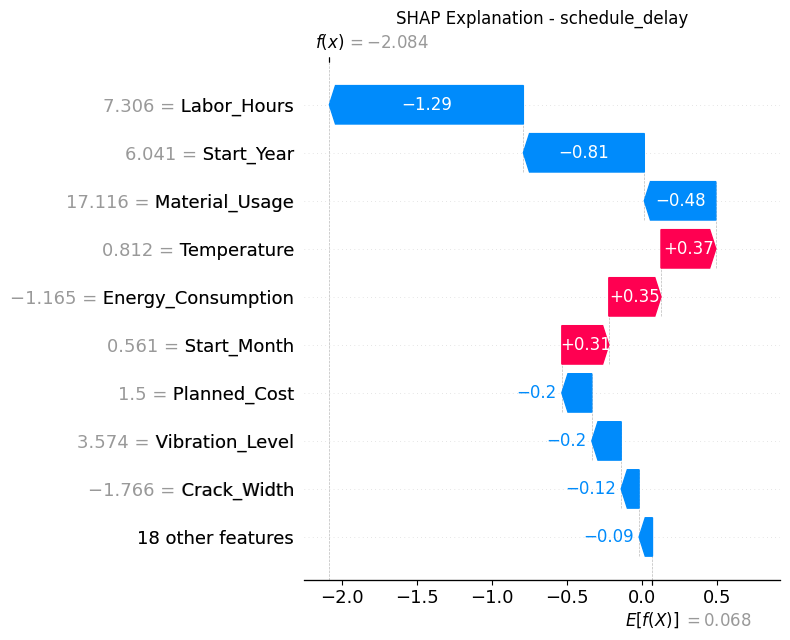


TOP FACTORS FOR SCHEDULE_DELAY
               Feature  SHAP_Value
9          Labor_Hours   -1.291673
2           Start_Year   -0.805297
8       Material_Usage   -0.476225
5          Temperature    0.365258
11  Energy_Consumption    0.347401
3          Start_Month    0.312813
0         Planned_Cost   -0.199701
14     Vibration_Level   -0.195642
15         Crack_Width   -0.119182
4        Start_Quarter   -0.080307


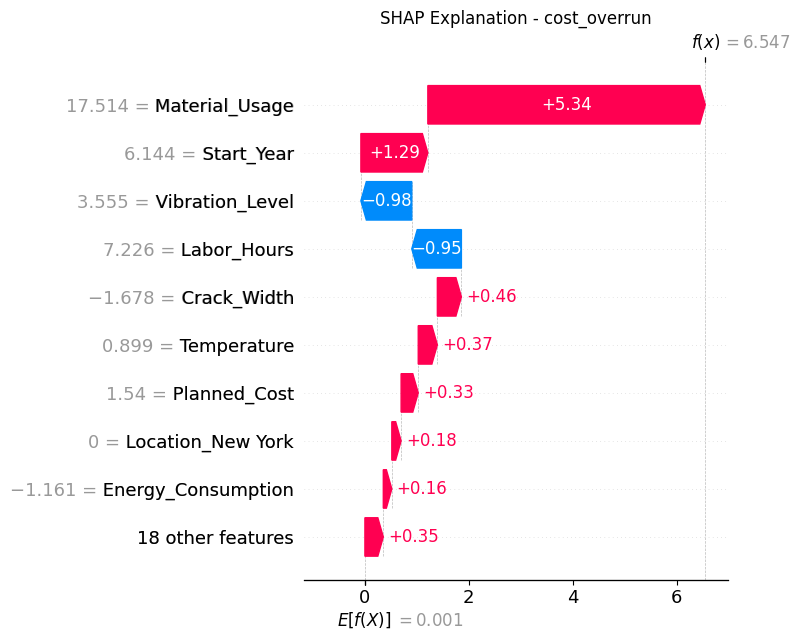


TOP FACTORS FOR COST_OVERRUN
               Feature  SHAP_Value
8       Material_Usage    5.335567
2           Start_Year    1.287664
14     Vibration_Level   -0.978656
9          Labor_Hours   -0.954207
15         Crack_Width    0.462247
5          Temperature    0.367540
0         Planned_Cost    0.329465
20   Location_New York    0.178631
11  Energy_Consumption    0.163866
12      Accident_Count    0.143197


SHAP ANALYSIS COMPLETED

Results saved in: shap_results/

Files generated:
schedule_delay_waterfall.png
schedule_delay_values.csv
cost_overrun_waterfall.png
cost_overrun_values.csv


In [2]:
# ============================================================
# CODE 6: SHAP EXPLANATION
# ============================================================

import os
import joblib
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. LOAD MODELS AND FEATURES
# ============================================================

delay_model = joblib.load(
    "models/best_delay_model.pkl"
)

cost_model = joblib.load(
    "models/best_cost_model.pkl"
)

delay_features = joblib.load(
    "models/delay_features.pkl"
)

cost_features = joblib.load(
    "models/cost_features.pkl"
)


# ============================================================
# 2. LOAD PROCESSED DATA FOR SHAP BACKGROUND
# ============================================================

df = pd.read_csv(
    "building_final_processed_data.csv"
)


# ============================================================
# 3. ENTER THE SAME NEW PROJECT USED IN CODE 3
# ============================================================

project = {

    "Planned_Cost": 50000000,

    "Planned_Duration": 600,

    "Start_Year": 2026,

    "Start_Month": 8,

    "Location": "Kanpur",

    "Weather_Condition": "Sunny",

    "Temperature": 32,

    "Humidity": 65,

    "Air_Quality_Index": 150,

    "Material_Usage": 5000,

    "Labor_Hours": 25000,

    "Equipment_Utilization": 75,

    "Energy_Consumption": 12000,

    "Accident_Count": 2,

    "Safety_Risk_Score": 6,

    "Vibration_Level": 3,

    "Crack_Width": 0.2,

    "Load_Bearing_Capacity": 300
}


project["Start_Quarter"] = (
    (project["Start_Month"] - 1) // 3 + 1
)


new_project = pd.DataFrame([project])


# ============================================================
# 4. FUNCTION FOR SHAP ANALYSIS
# ============================================================

def run_shap(model_pipeline, features, new_data, name):

    # Get preprocessing and trained model
    preprocessor = model_pipeline.named_steps[
        "preprocessor"
    ]

    model = model_pipeline.named_steps[
        "model"
    ]

    # Transform new project
    X_new = preprocessor.transform(
        new_data[features]
    )

    # Transform background data
    X_background = preprocessor.transform(
        df[features].sample(
            min(100, len(df)),
            random_state=42
        )
    )

    # Get transformed feature names
    feature_names = (
        preprocessor
        .get_feature_names_out(features)
    )

    X_new = pd.DataFrame(
        X_new,
        columns=feature_names
    )

    X_background = pd.DataFrame(
        X_background,
        columns=feature_names
    )

    # --------------------------------------------------------
    # Select SHAP explainer
    # --------------------------------------------------------

    if model.__class__.__name__ in [
        "RandomForestClassifier",
        "XGBClassifier"
    ]:

        explainer = shap.TreeExplainer(
            model
        )

    else:

        explainer = shap.LinearExplainer(
            model,
            X_background
        )

    # Calculate SHAP values
    shap_values = explainer(
        X_new
    )

    # --------------------------------------------------------
    # Handle binary classification output
    # --------------------------------------------------------

    if len(shap_values.values.shape) == 3:

        shap_values.values = (
            shap_values.values[:, :, 1]
        )

        if hasattr(
            shap_values,
            "base_values"
        ):

            if len(
                np.shape(
                    shap_values.base_values
                )
            ) == 2:

                shap_values.base_values = (
                    shap_values.base_values[:, 1]
                )

    # --------------------------------------------------------
    # Create output folder
    # --------------------------------------------------------

    os.makedirs(
        "shap_results",
        exist_ok=True
    )

    # --------------------------------------------------------
    # Waterfall plot
    # --------------------------------------------------------

    plt.figure(
        figsize=(10, 7)
    )

    shap.plots.waterfall(
        shap_values[0],
        max_display=10,
        show=False
    )

    plt.title(
        f"SHAP Explanation - {name}"
    )

    plt.tight_layout()

    plt.savefig(
        f"shap_results/{name}_waterfall.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # --------------------------------------------------------
    # Save SHAP values
    # --------------------------------------------------------

    shap_result = pd.DataFrame({

        "Feature": feature_names,

        "SHAP_Value":
            shap_values.values[0]

    })

    shap_result[
        "Absolute_SHAP"
    ] = shap_result[
        "SHAP_Value"
    ].abs()

    shap_result = (
        shap_result
        .sort_values(
            "Absolute_SHAP",
            ascending=False
        )
    )

    shap_result.to_csv(
        f"shap_results/{name}_values.csv",
        index=False
    )

    print("\n" + "=" * 60)

    print(
        f"TOP FACTORS FOR {name.upper()}"
    )

    print("=" * 60)

    print(
        shap_result[
            [
                "Feature",
                "SHAP_Value"
            ]
        ].head(10)
    )


# ============================================================
# 5. SHAP FOR SCHEDULE DELAY
# ============================================================

run_shap(

    delay_model,

    delay_features,

    new_project,

    "schedule_delay"

)


# ============================================================
# 6. SHAP FOR COST OVERRUN
# ============================================================

run_shap(

    cost_model,

    cost_features,

    new_project,

    "cost_overrun"

)


# ============================================================
# 7. FINAL MESSAGE
# ============================================================

print("\n")
print("=" * 60)
print("SHAP ANALYSIS COMPLETED")
print("=" * 60)

print(
    "\nResults saved in: shap_results/"
)

print(
    "\nFiles generated:"
)

print(
    "schedule_delay_waterfall.png"
)

print(
    "schedule_delay_values.csv"
)

print(
    "cost_overrun_waterfall.png"
)

print(
    "cost_overrun_values.csv"
)